In [1]:
import warnings
import pandas as pd
import plotly.express as px
from data import *

warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)

ts_user = 'ATa'
gitlab_user = 'andrzej.tarnowiecki'

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/oda/notebooks/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-5c47e8e3-e2dc-4a44-a42f-78115fbcd63a;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

# ATa

In [2]:
user_issues(ts_user).toPandas()

25/06/06 07:33:23 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

,key,summary,status,type,priority,size,size_points,status_changed_at,issue_total_hours,user_total_hours
0,CRYP-10672,Airflow kolejkowanie wykonywanych zadań,Delivered,Story,Medium,None,None,2025-06-02 06:31:11.748,3.0,3.0
1,CRYP-10611,Dostosowanie compaction strategy dla tabeli co...,Delivered,Story,Medium,None,None,2025-06-02 06:29:07.984,7.5,7.5
2,CRYP-10734,Zbieranie logów z fail2ban i OpenVPN do Grayloga,In Progress,Story,Medium,None,None,2025-05-30 12:35:56.818,1.0,1.0
3,CRYP-10608,Wykonywanie kopi mongodb,Done,Story,Medium,None,None,2025-05-29 10:31:12.821,3.0,3.0
4,CRYP-10673,[Mexc] Przygotowanie produkcji do wdrożenia tr...,Done,Story,High,None,None,2025-05-22 08:38:13.853,19.0,10.5
5,CRYP-8936,Gitlab/Nexus przez HTTPS,Done,Story,Medium,None,None,2025-05-21 06:42:36.639,73.0,68.5
6,CRYP-10532,Cassandra Problemy z zasobami,In Progress,Story,Medium,None,None,2025-05-15 10:24:16.197,36.5,36.5
7,CRYP-10627,[Release-verifier] Program nie kończy się po u...,Will not do,Bug,High,None,None,2025-05-05 05:43:33.270,1.5,1.5
8,CRYP-8500,Usunięcie serwerów pyspark-notebook,In Progress,Story,Medium,None,None,2025-04-30 07:45:51.985,1.0,1.0
9,CRYP-10607,Jenkins potrafi budować kontenery dockerowe w ...,Done,Story,Medium,XS,1,2025-04-30 06:42:33.341,6.5,3.5


In [3]:
user_issues_hours_monthly(ts_user).toPandas()

,month,jira_id,summary,status,hours
0,2025-06-01,CRYP-10532,Cassandra Problemy z zasobami,In Progress,1.5
1,2025-05-01,CRYP-10532,Cassandra Problemy z zasobami,In Progress,35.0
2,2025-05-01,CRYP-10611,Dostosowanie compaction strategy dla tabeli co...,Delivered,4.5
3,2025-05-01,CRYP-10672,Airflow kolejkowanie wykonywanych zadań,Delivered,3.0
4,2025-05-01,CRYP-10673,[Mexc] Przygotowanie produkcji do wdrożenia tr...,Done,10.5
5,2025-05-01,CRYP-10734,Zbieranie logów z fail2ban i OpenVPN do Grayloga,In Progress,1.0
6,2025-05-01,CRYP-8500,Usunięcie serwerów pyspark-notebook,In Progress,1.0
7,2025-05-01,CRYP-8936,Gitlab/Nexus przez HTTPS,Done,9.5
8,2025-04-01,CRYP-10195,[Swarm] Error while deleting neighbor entry,Done,1.0
9,2025-04-01,CRYP-10289,Ograniczenie ilości alertów na google chat.,Delivered,2.0


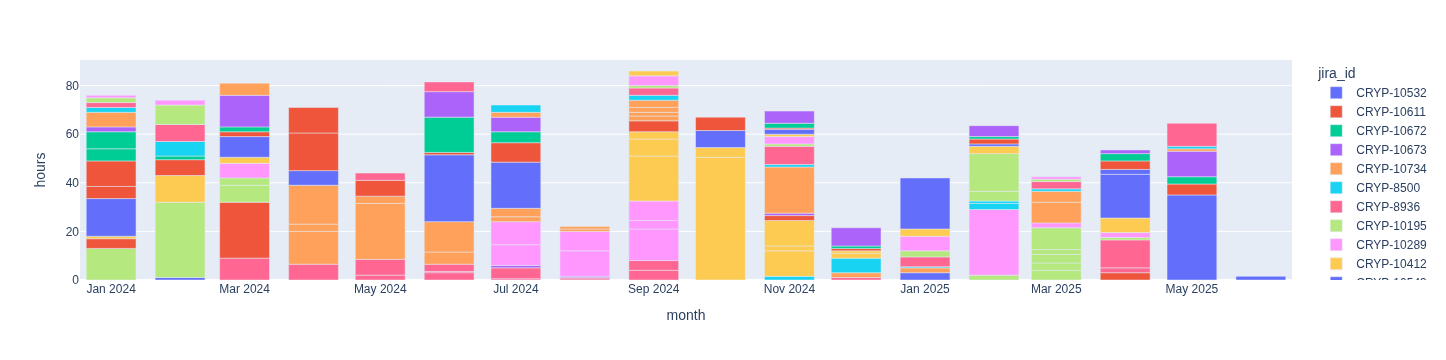

In [4]:
px.bar(user_issues_hours_monthly(ts_user).toPandas(),x='month',y='hours',color='jira_id',hover_data={'summary':True})

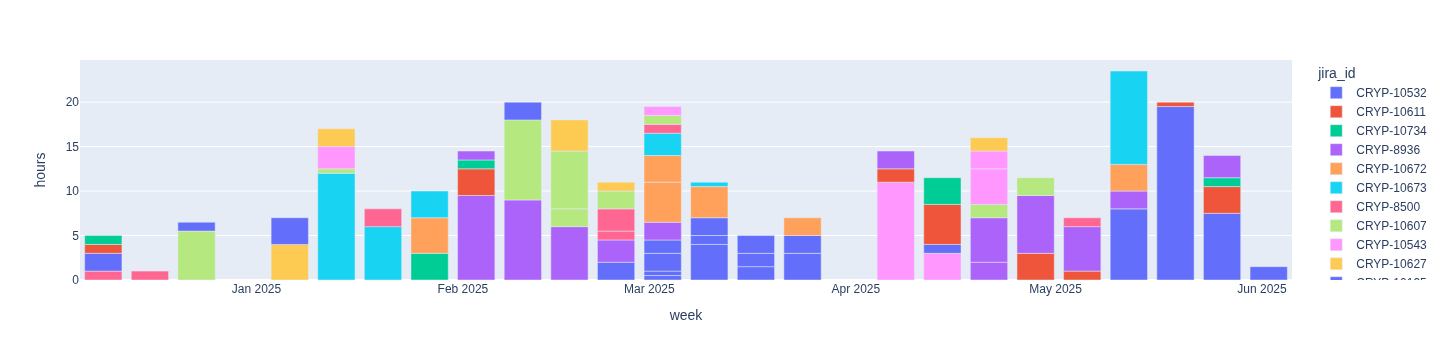

In [5]:
px.bar(user_issues_hours_weekly(ts_user).toPandas(),x='week',y='hours',color='jira_id',hover_data={'summary':True})

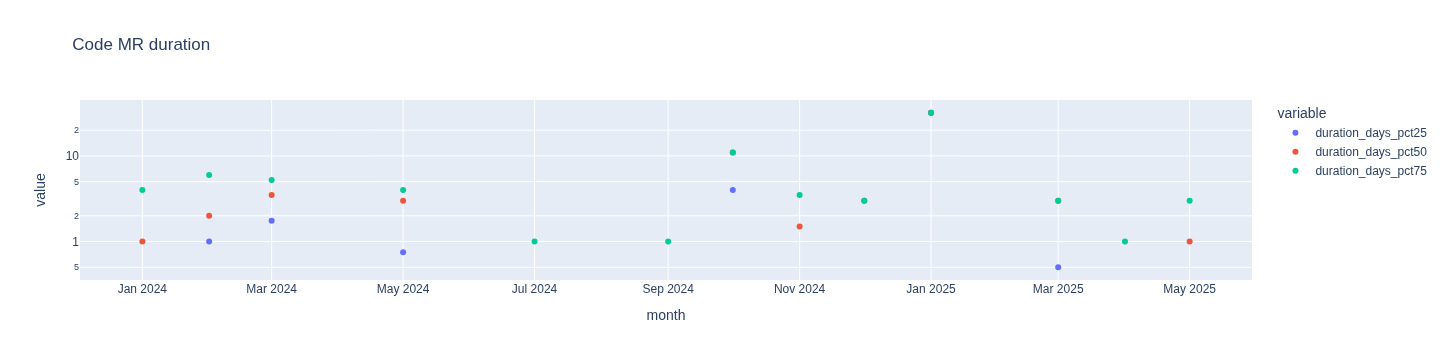

In [6]:
px.scatter(user_mrs_duration(gitlab_user).toPandas(),x='month',y=['duration_days_pct25','duration_days_pct50','duration_days_pct75'], log_y=True,title='Code MR duration')

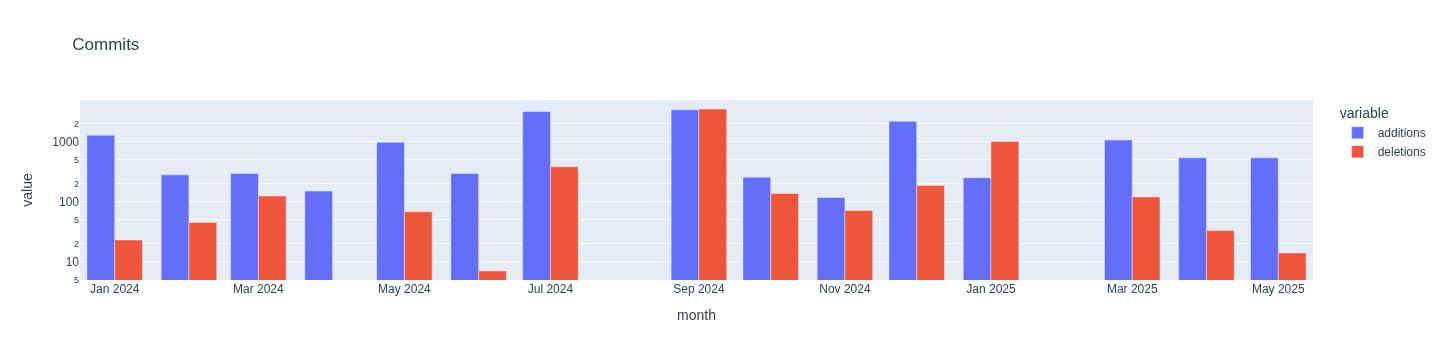

In [10]:
px.bar(user_code_commits(gitlab_user).toPandas(),x='month',y=['additions','deletions'],log_y=True,title='Commits',barmode='group')

In [8]:
users_hours.where(f.col('user')==ts_user).toPandas()

,month,user,jira_hours,other_hours,total_hours,other_hours_pct
0,2025-06-01,ATa,4.5,11.5,16.0,71.875000
1,2025-05-01,ATa,67.0,93.0,160.0,58.125000
2,2025-04-01,ATa,127.0,41.0,168.0,24.404762
3,2025-03-01,ATa,114.5,45.5,160.0,28.437500
4,2025-02-01,ATa,140.5,19.5,160.0,12.187500
5,2025-01-01,ATa,131.5,12.5,144.0,8.680556
6,2024-12-01,ATa,124.0,30.0,154.0,19.480519
7,2024-11-01,ATa,124.5,19.5,144.0,13.541667
8,2024-10-01,ATa,148.0,14.0,162.0,8.641975
9,2024-09-01,ATa,86.0,82.0,168.0,48.809524


In [9]:
user_other_hours(ts_user).toPandas()

,month,task_desc,other_hours
0,2025-06-01,code review,1.0
1,2025-06-01,meet,4.5
2,2025-06-01,support,2.0
3,2025-06-01,"hdfs ,analiza reaper,brak miejsca, czyszczenie",4.0
4,2025-05-01,swarm3.platform awaria sieci,2.0
5,2025-05-01,nowy hdfs-node19,2.0
6,2025-05-01,"hdfs brak miejsca, czyszczenie",1.5
7,2025-05-01,pyspark-ServiceDwon awaria,1.0
8,2025-05-01,code review,9.0
9,2025-05-01,"vault dodanie usera ldap, vaultier",3.0
